In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

df=pd.read_csv('data/manutencao_preditiva.csv')
print('Dataset carregado com sucesso.')

Dataset carregado com sucesso.


# FASE 1: ANÁLISE EXPLORATÓRIA (EDA)

In [18]:
n_linhas, n_colunas = df.shape
print (f'O DataFrame possui {n_linhas} linhas e {n_colunas} colunas.')
print()
df.info()
display(df.head())
display(df.describe())

O DataFrame possui 10000 linhas e 14 colunas.

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  str    
 2   tipo                     10000 non-null  str    
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


,udi,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,10000.00000,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


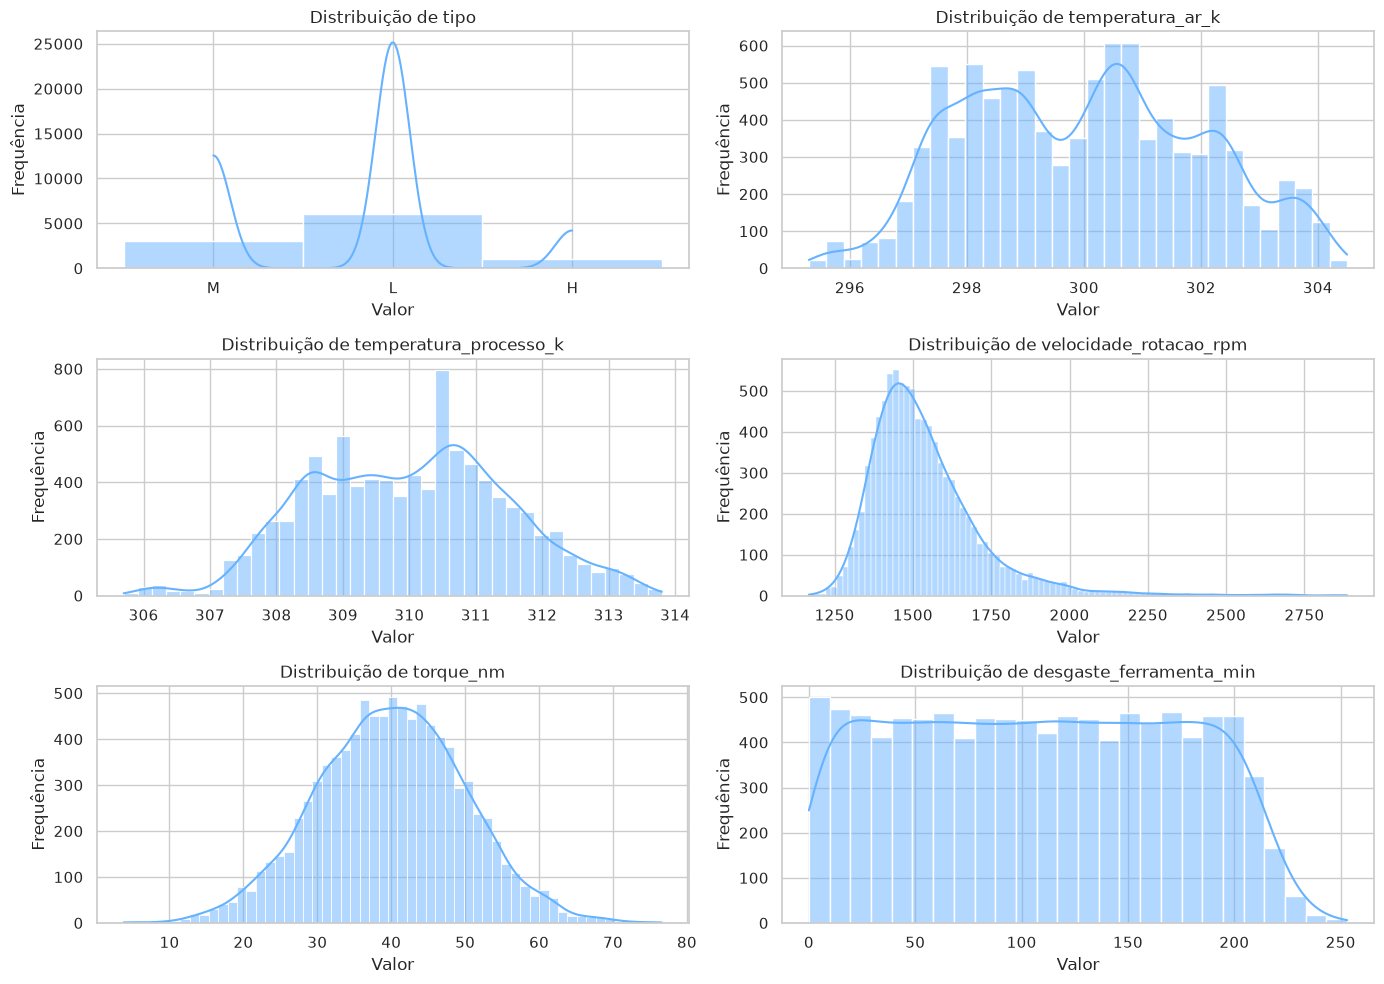

In [19]:
# PLOTANDO GRÁFICO DE DISTRIBUIÇÃO DE VARIÁVEIS PREDITORAS

# Selecionando as colunas preditoras numéricas principais
colunas_num = ['tipo', 'temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']

fig, axes = plt.subplots(3,2, figsize=(14, 10))
axes = axes.flatten()

for i, coluna in enumerate(colunas_num):
    sns.histplot(df[coluna], kde=True, ax=axes[i], color='#66B2FF')
    axes[i].set_title(f'Distribuição de {coluna}', fontsize=12)
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

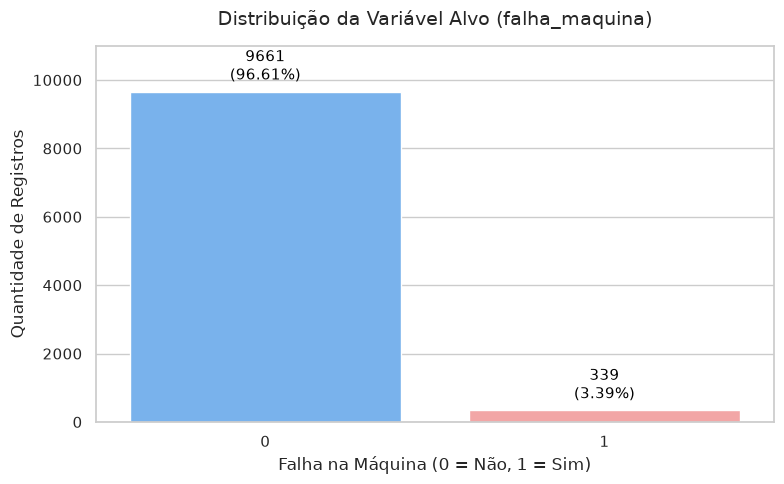

In [20]:
# PLOTANDO GRÁFICO DE BARRAS COMPROVANDO TAXA DE DESBALANCEAMENTO DA VARIÁVEL ALVO
import matplotlib.pyplot as plt
import seaborn as sns

# Configura o estilo visual
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Conta a quantidade de cada classe na variável alvo (evitando o FutureWarning usando hue e legend=False)
ax = sns.countplot(x='falha_maquina', data=df, hue='falha_maquina', palette=['#66B2FF', '#FF9999'], legend=False)

# Adiciona os valores absolutos e as porcentagens em cima das barras
total = len(df['falha_maquina'])
for p in ax.patches:
    height = p.get_height()
    percentage = (height / total) * 100
    ax.annotate(f'{height:.0f}\n({percentage:.2f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Distribuição da Variável Alvo (falha_maquina)', fontsize=14, pad=15)
plt.xlabel('Falha na Máquina (0 = Não, 1 = Sim)', fontsize=12)
plt.ylabel('Quantidade de Registros', fontsize=12)
plt.ylim(0, total * 1.1)  # Ajusta o limite do eixo Y para dar espaço ao texto

plt.tight_layout()
plt.show()

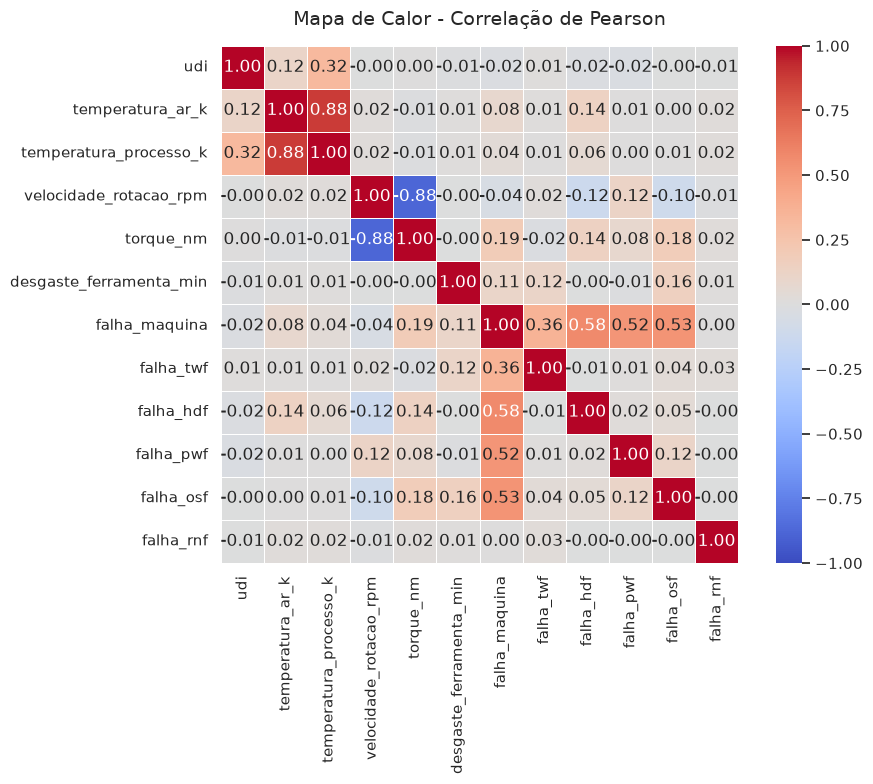

In [21]:
# PLOTANDO MAPA DE CALOR COM CORRELAÇÃO DE PEARSON ENTRE AS VARIÁVEIS

# Selecionando apenas as colunas numéricas para o cálculo da correlação
colunas_numericas = df.select_dtypes(include=['float64', 'int64', 'int32'])

# Calculando a matriz de correlação de Pearson
corr_matrix = colunas_numericas.corr(method='pearson')

# Configurando o tamanho da figura
plt.figure(figsize=(10, 8))

# Criando o mapa de calor (heatmap)
sns.heatmap(
    corr_matrix,
    annot=True,          # Exibe os valores de correlação nos quadrados
    fmt=".2f",           # Limita a 2 casas decimais
    cmap='coolwarm',     # Paleta de cores divergente (azul para negativo, vermelho para positivo)
    vmin=-1, vmax=1,     # Define os limites da escala de cor
    square=True,         # Força os blocos a serem quadrados
    linewidths=0.5       # Linha fina divisória entre os blocos
)

# Ajustes de título e exibição
plt.title('Mapa de Calor - Correlação de Pearson', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

**Análise dos Gráficos e Direcionamento da Modelagem**

Com base nas visualizações geradas na Fase 1 (EDA), podemos extrair conclusões críticas que direcionam a nossa abordagem de preparação e modelagem:

1- Distribuição das Variáveis Preditoras:  
`velocidade_rotacao_rpm` possui uma assimetria à direita (cauda longa) com presença marcante de outliers na extremidade superior (valores acima de ~1900 RPM). Isso indica a necessidade de tratá-los para evitar impactos negativos em modelos sensíveis a extremos, ou optar por técnicas robustas.
`torque_nm` e as temperaturas apresentam distribuições razoavelmente simétricas, próximas à normal.
`desgaste_ferramenta_min` possui uma distribuição uniforme, indicando que o desgaste é monitorado de forma linear e contínua ao longo do tempo.


2- Desbalanceamento Crítico da Variável Alvo `falha_maquina`:  
Apenas 3.39% dos registros representam falhas (339 de 10.000). Um desbalanceamento tão relevante induz qualquer classificador tradicional a simplesmente ignorar a classe minoritária e ainda obter ~96.6% de acurácia global.
Direcionamento: Métricas de avaliação como Recall, F1-Score e AUC-ROC serão prioritárias sobre a Acurácia pura. Além disso, a aplicação de técnicas de sobreamostragem (como o SMOTE) nos dados de treino é indispensável.


3- Correlações e Multicolinearidade (Mapa de Calor):  
Forte Correlação Positiva (0.88): Entre `temperatura_ar_k` e `temperatura_processo_k`. Isso é esperado fisicamente, mas pode causar redundância (multicolinearidade).
Forte Correlação Negativa (-0.88): Entre `velocidade_rotacao_rpm` e `torque_nm`. A física de rotação explica essa relação inversa perfeita (potência constante implica torque menor para rotações maiores).
Associação com Falha: Nenhuma variável isolada possui forte correlação linear direta com `falha_maquina`. A maior é torque com 0.19. 
Isso mostra que as falhas são causadas por combinações **NÃO LINEARES** de múltiplos fatores, justificando o uso de algoritmos robustos como *Random Forest* ou *KNN* para capturar essas interações complexas.

### FASE 2: LIMPEZA E TRATAMENTO DE DADOS (DATA PREP)

In [22]:
# Identificando linhas duplicadas

if df.duplicated().sum()==0:
  print ("Não há linhas duplicadas")
else:
  print ("Há linhas duplicadas")

Não há linhas duplicadas


In [23]:
# Excluindo colunas que não são úteis e podem prejudicar o treinamento do modelo preditivo

df_col_uteis = df.drop(columns=['udi', 'id_produto', 'falha_twf', 'falha_hdf', 'falha_pwf', 'falha_osf', 'falha_rnf'])

n_linhas, n_colunas = df_col_uteis.shape
print(f"O novo DataFrame está com {n_linhas} linhas e {n_colunas} colunas.")

O novo DataFrame está com 10000 linhas e 7 colunas.


In [24]:
# IDENTIFICANDO OUTLIERS

for coluna in ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']:
    Q1 = df_col_uteis[coluna].quantile(0.25)
    Q3 = df_col_uteis[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df_col_uteis[(df_col_uteis[coluna] < limite_inferior) | (df_col_uteis[coluna] > limite_superior)]
    print(f"A feature {coluna} está com {len(outliers)} outliers")
    print()

A feature temperatura_ar_k está com 0 outliers

A feature temperatura_processo_k está com 0 outliers

A feature velocidade_rotacao_rpm está com 398 outliers

A feature torque_nm está com 63 outliers

A feature desgaste_ferramenta_min está com 0 outliers



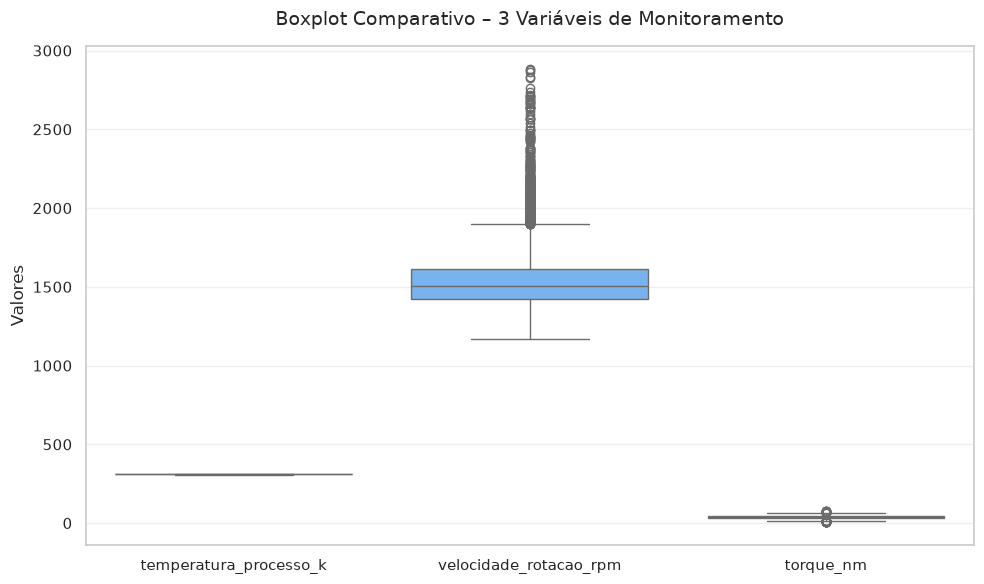

In [25]:
# DEMONSTRANDO OUTLIERS GRAFICAMENTE

plt.figure(figsize=(10, 6))

# Definindo as cores personalizadas correspondentes às 3 variáveis do gráfico
colors = ['#FF9999', '#66B2FF', '#99FF99']

# Criando o boxplot com o Seaborn que suporta orientação e paleta de cores facilmente
sns.boxplot(
    data=df[['temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']],
    orient='v',
    palette=colors
)

# Ajustando títulos e rótulos
plt.title('Boxplot Comparativo – 3 Variáveis de Monitoramento', fontsize=14, pad=15)
plt.ylabel('Valores', fontsize=12)
plt.grid(axis='y', alpha=0.3)           # linha de grade leve
plt.tight_layout()                      # melhora posicionamento
plt.show()

### Imputação de Valores Nulos:

* **MÉDIA:** Aplicada às features simétricas e livres de outliers `temperatura_ar_k` e `temperatura_processo_k`, pois a média é estatisticamente o melhor estimador central para distribuições bem comportadas.

* **MEDIANA:** Aplicada às features com assimetria ou presença de outliers `velocidade_rotacao_rpm` e `torque_nm`, garantindo que o valor de preenchimento não seja distorcido pelos extremos da distribuição.

In [26]:
# IDENTIFICANDO VALORES NULOS

df_col_uteis.isna().sum()

tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
dtype: int64

In [27]:
# SUBSTITUINDO VALORES NULOS

# Valores nulos foram substituídos pela MÉDIA, pois não há outliers nas colunas 'temperatura_ar_k' e 'temperatura_processo_k'
for coluna in ['temperatura_ar_k', 'temperatura_processo_k']:
    df_col_uteis[coluna]=df_col_uteis[coluna].fillna(df_col_uteis[coluna].mean())

# Valores nulos foram subastituídos pela MEDIANA, pois HÁ outliers nas colunas 'velocidade_rotação_rpm' e 'torque_nm', o que pode comprometer o cálculo da média.
for coluna in ['velocidade_rotacao_rpm', 'torque_nm']:
    df_col_uteis[coluna]=df_col_uteis[coluna].fillna(df_col_uteis[coluna].median())

display(df_col_uteis.isna().sum())

tipo                       0
temperatura_ar_k           0
temperatura_processo_k     0
velocidade_rotacao_rpm     0
torque_nm                  0
desgaste_ferramenta_min    0
falha_maquina              0
dtype: int64

### Tratamento Misto de Outliers

Seguindo a estratégia definida:
1. **Exclusão** dos registros que contêm outliers na coluna de velocidade (`velocidade_rotacao_rpm`).

2. **Clipping** (Winsorization) dos valores extremos na coluna de torque (`torque_nm`). Para evitar a perda de mais dados, em vez de remover as linhas, faremos o **clipping** dos valores extremos. Essa técnica limita os valores máximos e mínimos das features aos limites inferior e superior estabelecidos pelo método de amplitude interquartílica (IQR).

In [28]:
# 1. EXCLUSÃO DE LINHAS COM OUTLIERS NA COLUNA 'velocidade_rotacao_rpm'
Q1_vel = df_col_uteis['velocidade_rotacao_rpm'].quantile(0.25)
Q3_vel = df_col_uteis['velocidade_rotacao_rpm'].quantile(0.75)
IQR_vel = Q3_vel - Q1_vel

limite_inf_vel = Q1_vel - 1.5 * IQR_vel
limite_sup_vel = Q3_vel + 1.5 * IQR_vel

# Filtrando apenas os registros dentro dos limites
df_limpo = df_col_uteis[(df_col_uteis['velocidade_rotacao_rpm'] >= limite_inf_vel) & (df_col_uteis['velocidade_rotacao_rpm'] <= limite_sup_vel)]

n_linhas, n_colunas = df_limpo.shape
print(f"Após a exclusão de outliers, o DataFrame possui {n_linhas} linhas e {n_colunas} colunas.")

Após a exclusão de outliers, o DataFrame possui 9535 linhas e 7 colunas.


In [29]:
# 2. CLIPPING DE OUTLIERS DA COLUNA 'torque_nm'
Q1_tor = df_limpo['torque_nm'].quantile(0.25)
Q3_tor = df_limpo['torque_nm'].quantile(0.75)
IQR_tor = Q3_tor - Q1_tor

limite_inf_tor = Q1_tor - 1.5 * IQR_tor
limite_sup_tor = Q3_tor + 1.5 * IQR_tor

# Aplicando o clipping utilizando .loc para evitar SettingWithCopyWarning
df_limpo.loc[:, 'torque_nm'] = df_limpo['torque_nm'].clip(lower=limite_inf_tor, upper=limite_sup_tor)

n_linhas, n_colunas = df_limpo.shape
print('Winsorization realizada com sucesso.')
print()
print(f"O DataFrame mantém {n_linhas} linhas e {n_colunas} colunas.")

Winsorization realizada com sucesso.

O DataFrame mantém 9535 linhas e 7 colunas.


### Abordagem para a coluna `tipo`: Ordinal Encoding

Como a coluna `tipo` (L, M, H) possui valores que indicam uma ordem de qualidade/robustez do maquinário, utilizaremos o mapeamento ordinal em vez de criar variáveis dummies.

In [30]:
# Criando uma cópia explícita para evitar qualquer SettingWithCopyWarning
df_limpo = df_limpo.copy()

# Criando o mapeamento ordinal para a coluna 'tipo' utilizando .loc
mapeamento_tipo = {'L': 0, 'M': 1, 'H': 2}
df_limpo.loc[:, 'tipo_ordinal'] = df_limpo['tipo'].map(mapeamento_tipo)

# Descartando a coluna original 'tipo'
df_final = df_limpo.drop(columns=['tipo'])

display(df_final.head())

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,tipo_ordinal
0,298.100000,308.600000,1551.0,42.8,0,0,1
1,298.200000,308.700000,1408.0,46.3,3,0,0
2,298.100000,308.500000,1498.0,49.4,5,0,0
3,300.002158,310.000895,1504.0,40.1,7,0,0
4,298.200000,308.700000,1408.0,40.0,9,0,0


### FASE 3: FEATURE ENGINEERING

In [31]:
df_final['potencia'] = df_final['velocidade_rotacao_rpm'] * df_final['torque_nm']

display (df_final.head(10))
print()
n_linhas, n_colunas = df_final.shape
print(f"Após a criação da coluna 'potencia', o DataFrame Final possui {n_linhas} linhas e {n_colunas} colunas.")

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,tipo_ordinal,potencia
0,298.100000,308.600000,1551.0,42.8,0,0,1,66382.8
1,298.200000,308.700000,1408.0,46.3,3,0,0,65190.4
2,298.100000,308.500000,1498.0,49.4,5,0,0,74001.2
3,300.002158,310.000895,1504.0,40.1,7,0,0,60310.4
4,298.200000,308.700000,1408.0,40.0,9,0,0,56320.0
5,298.100000,308.600000,1425.0,41.9,11,0,1,59707.5
6,298.100000,308.600000,1558.0,42.4,14,0,0,66059.2
7,298.100000,308.600000,1527.0,40.2,16,0,0,61385.4
8,298.300000,308.700000,1667.0,28.6,18,0,1,47676.2
9,298.500000,309.000000,1741.0,28.0,21,0,1,48748.0



Após a criação da coluna 'potencia', o DataFrame Final possui 9535 linhas e 8 colunas.


### FASE 4: DIVISÃO E BALANCEAMENTO DOS DADOS

In [32]:
# SEPARANDO VARIÁVEIS PREDITORAS E VARIÁVEL ALVO

X = df_final.drop(columns=['falha_maquina'])
y = df_final['falha_maquina']

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Separação dos dados em 'X' e 'y' realizada com sucesso.")

Separação dos dados em 'X' e 'y' realizada com sucesso.


In [33]:
# DIVIDINDO OS DADOS EM TREINO E TESTE. O parâmetro nominal "stratify=y" preserva a proporção das classes em ambas as partes.

X_treino, X_teste, y_treino, y_teste = train_test_split (X, y, test_size=0.2, random_state=42, stratify=y)

print("Divisão dos dados em 'Treino' e 'Teste' realizada com sucesso.")

Divisão dos dados em 'Treino' e 'Teste' realizada com sucesso.


In [34]:
# APLICANDO REAMOSTRAGEM SOMENTE NOS DADOS DE TREINO

smote = SMOTE(random_state=42)

X_treino_reamostrado, y_treino_reamostrado = smote.fit_resample(X_treino, y_treino)

print('Reamostragem dos dados de treino realizada com sucesso.')

Reamostragem dos dados de treino realizada com sucesso.


### FASE 5: ESCALONAMENTO DE VARIÁVEIS (**StandardScaler**)

In [35]:
# 1. Criar e aplicar o scaler

scaler = StandardScaler()

X_treino_scalonado = scaler.fit_transform(X_treino_reamostrado)  # Aplica-se fit + transform no TREINO
X_teste_scalonado = scaler.transform(X_teste)                    # Aplica-se apenas transform no TESTE

print('Escalonamento das variáveis realizado com sucesso.')

Escalonamento das variáveis realizado com sucesso.


In [36]:
# Como X_treino_scalonado é uma matriz NumPy, usamos fatiamento [:5] em vez de .head()

print("Visualizando as primeiras 5 linhas dos dados escalonados (matriz NumPy):")
print(X_treino_scalonado[:10])

Visualizando as primeiras 5 linhas dos dados escalonados (matriz NumPy):
[[-1.48949268 -1.11567886 -0.65456439  0.34468585  0.24503233 -0.5684236
   0.22061186]
 [-0.31616986 -0.33923534  2.0125761  -1.61930344 -0.49957142 -0.5684236
  -1.50342166]
 [ 0.05716013  0.98071865 -0.45959798  0.46343869 -0.89466729  1.17534037
   0.49367962]
 [-1.2228284  -0.96039016 -1.06009452  0.34468585 -0.28682749 -0.5684236
  -0.01327351]
 [-1.7028241  -1.27096757  1.59144865 -1.23564041  1.21757601  2.91910435
  -1.02597976]
 [ 1.07048439  1.29129606  1.52126075 -0.87938189  1.03522407  1.17534037
  -0.4826976 ]
 [-1.06282984 -0.96039016 -0.45179932  0.1437195  -0.40839545 -0.5684236
   0.06553569]
 [ 0.2171587   1.29129606 -0.24903426 -0.31302219  1.46071193 -0.5684236
  -0.45238637]
 [-1.54282554 -1.11567886 -0.32702082 -0.3952357   0.27542432 -0.5684236
  -0.60352474]
 [ 0.32382441  0.82542994 -0.42840335 -0.5048537  -1.68485903  1.17534037
  -0.80132998]]
